In [2]:
#importing libraries
import os
import pandas as pd
import torch
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
from torchvision import models
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [4]:
#loading the csv file from dataset
metadata = pd.read_csv(r"E:\biomedical engineering\xray dataset\shenzhen_metadata.csv")
metadata['label'] = metadata['findings'].apply(lambda x: 0 if 'Normal' in x else 1)

In [6]:

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_filename = self.df.iloc[idx]['study_id']  # uses correct column
        img_path = os.path.join(self.img_dir, img_filename)
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = 0 if self.df.iloc[idx]['findings'].lower() == "normal" else 1
        return image, label

In [8]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)  # For MobileNetV2
])

In [22]:
train_df = pd.read_csv(r"E:\biomedical engineering\xray dataset\shenzhen_metadata.csv")

dataset = ChestXrayDataset(train_df, img_dir=r"E:\biomedical engineering\xray dataset\images\images", transform=transform)
train_loader = DataLoader(dataset, batch_size=16, shuffle=True)
train_df.head()

In [12]:
train_df.head()

,study_id,sex,age,findings
0,CHNCXR_0001_0.png,Male,45,normal
1,CHNCXR_0002_0.png,Male,63,normal
2,CHNCXR_0003_0.png,Female,48,normal
3,CHNCXR_0004_0.png,Male,58,normal
4,CHNCXR_0005_0.png,Male,28,normal


In [24]:
#initiaing the training and validating datasets 
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=0)

In [26]:
#initiating the mobilenet.v2 pretrained model
model = models.mobilenet_v2(pretrained=False)  
model.classifier[1] = torch.nn.Linear(model.last_channel, 2) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

E:\anaconda\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
E:\anaconda\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [28]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [30]:
#training the model
for epoch in range(5):  
    model.train()
    running_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    
    print(f"Epoch {epoch+1} - Loss: {running_loss / len(train_loader):.4f}")

Epoch 1 - Loss: 0.6739
Epoch 2 - Loss: 0.6574
Epoch 3 - Loss: 0.6243
Epoch 4 - Loss: 0.6307
Epoch 5 - Loss: 0.6021



 Validation Accuracy: 0.7895
 AUC Score: 0.8422


Text(0.5, 1.0, 'Confusion Matrix')

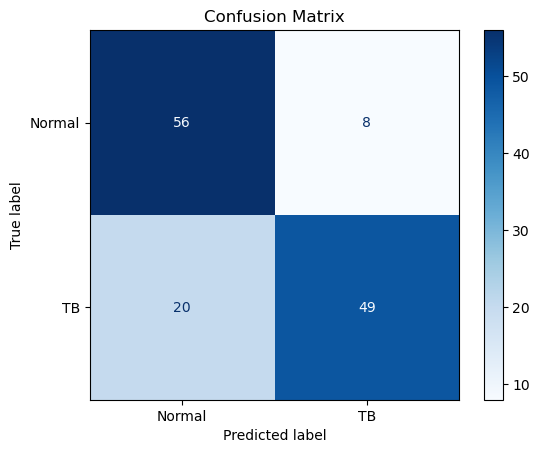

In [32]:
#evaluating the model with metrics 
model.eval()
all_preds, all_probs, all_labels = [], [], []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
acc = accuracy_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)
cm = confusion_matrix(all_labels, all_preds)

print(f"\n Validation Accuracy: {acc:.4f}")
print(f" AUC Score: {auc:.4f}")
disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "TB"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")


In [54]:
import matplotlib.pyplot as plt

def diagnose_image(image_path, model, transform, device):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device) 

    with torch.no_grad():
        output = model(image_tensor)
        prob = torch.softmax(output, dim=1)[0][1].item()
        pred_class = torch.argmax(output, dim=1).item()

    label_str = "TB manifestation detected; lung lesion" if pred_class == 1 else "Normal"

    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Prediction: {label_str}\nTB Probability: {prob:.4f}", fontsize=14)
    plt.show()
    print(f"\n Image: {image_path}")
    print(f" Predicted Condition: {label_str}")
    print(f" TB Probability: {prob:.4f}")


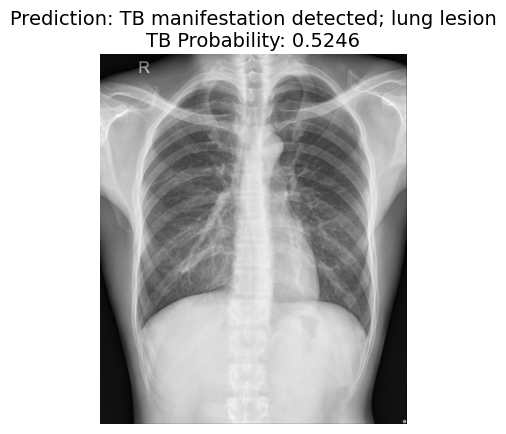


 Image: E:\biomedical engineering\xray dataset\images\images\CHNCXR_0501_1.png
 Predicted Condition: TB manifestation detected; lung lesion
 TB Probability: 0.5246


In [56]:

example_img_filename = train_df.iloc[500]['study_id']  
example_img_path = os.path.join(r"E:\biomedical engineering\xray dataset\images\images", example_img_filename)

diagnose_image(example_img_path, model, transform, device)


In [ ]:
import os
import pandas as pd
import torch
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
from torchvision import models
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Load metadata
metadata = pd.read_csv("/mnt/data/shenzhen_metadata.csv")
metadata['label'] = metadata['findings'].apply(lambda x: 0 if 'Normal' in x else 1)

# Dataset class
class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_filename = self.df.iloc[idx]['study_id']  # uses correct column
        img_path = os.path.join(self.img_dir, img_filename)
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = 0 if self.df.iloc[idx]['findings'].lower() == "normal" else 1
        return image, label

# Transform
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)  # For MobileNetV2
])

# Dataset
train_df = pd.read_csv(r"E:\biomedical engineering\xray dataset\shenzhen_metadata.csv")

dataset = ChestXrayDataset(train_df, img_dir=r"E:\biomedical engineering\xray dataset\images\images", transform=transform)
train_loader = DataLoader(dataset, batch_size=16, shuffle=True)

# Train/val split
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=0)

# Model: MobileNetV2
model = models.mobilenet_v2(pretrained=False)  
model.classifier[1] = torch.nn.Linear(model.last_channel, 2) 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Loss & Optimizer
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Training loop
for epoch in range(5):  # You can increase this
    model.train()
    running_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    
    print(f"Epoch {epoch+1} - Loss: {running_loss / len(train_loader):.4f}")

# Evaluation
model.eval()
all_preds, all_probs, all_labels = [], [], []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Metrics
acc = accuracy_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)
cm = confusion_matrix(all_labels, all_preds)

print(f"\n Validation Accuracy: {acc:.4f}")
print(f" AUC Score: {auc:.4f}")

# Confusion Matrix
disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "TB"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

# Save model
torch.save(model.state_dict(), "tb_mobilenet_model.pth")
print("Model saved as 'tb_mobilenet_model.pth'")  this is a code for training a model on a chestxray dataset from shenzhen, 